# 1. Carregamento de Dados Periféricos (WINGS / SPA-fNIRS)
Leitura do ficheiro estruturado `.wings` e conversão para um *DataFrame* do Pandas. O ficheiro contém os sinais de Resposta Galvânica da Pele (GSR) e Frequência Cardíaca (HR), bem como a linha de tempo em segundos (`SecondsSinceRunStart`) e os marcadores de estímulo (`Triggers`) sincronizados pelo hardware da NIRx.

In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Definir caminhos (apontando para a pasta extraída do ficheiro zip)
BASE_DIR = r"C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI"
SUJEITO = "sub-001"
RUN = "sub-001_ses-01_tk-dm_run-1_nirs_001"
WINGS_FILE = "2026-08-04_002.wings"

caminho_wings = os.path.join(BASE_DIR, SUJEITO, "nirs", RUN, "dados_wings_extraidos", WINGS_FILE)

print(f"A tentar ler o ficheiro WINGS:\n{caminho_wings}")

# 2. Ler as primeiras linhas do ficheiro para perceber a estrutura
# O ficheiro .wings costuma ser um ficheiro de texto separado por vírgulas ou tabulações
try:
    # Vamos ler apenas as primeiras 20 linhas para inspecionar o cabeçalho
    with open(caminho_wings, 'r') as f:
        cabecalho = [next(f) for x in range(20)]
    
    print("\n--- Primeiras 20 linhas do ficheiro .wings ---")
    for linha in cabecalho:
        print(linha.strip())
        
except FileNotFoundError:
    print("ERRO: Ficheiro não encontrado. Verifica o caminho.")
except Exception as e:
    print(f"Ocorreu um erro ao ler o ficheiro: {e}")

A tentar ler o ficheiro WINGS:
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\nirs\sub-001_ses-01_tk-dm_run-1_nirs_001\dados_wings_extraidos\2026-08-04_002.wings

--- Primeiras 20 linhas do ficheiro .wings ---
generation=2
Timestamp;SecondsSinceRunStart;Triggers;BatteryLevel;GSR;Unused;Unused;Unused;Unused;Unused;Unused;Unused;PPG;SpO2;HR
2026-08-04T14:08:30.156774;0.0984175;0;0.428;6.088313;0.000000;0.000000;0.000000;0.000000;0.000000;0.000000;0.000000;16.510000;99.000000;96.000000
2026-08-04T14:08:30.158774;0.1004175;0;0.428;6.088031;0.000000;0.000000;0.000000;0.000000;0.000000;0.000000;0.000000;16.510000;99.000000;96.000000
2026-08-04T14:08:30.160774;0.1024175;0;0.428;6.086812;0.000000;0.000000;0.000000;0.000000;0.000000;0.000000;0.000000;16.510000;99.000000;96.000000
2026-08-04T14:08:30.162774;0.1044175;0;0.428;6.086906;0.000000;0.000000;0.000000;0.000000;0.000000

A carregar o ficheiro WINGS:
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\nirs\sub-001_ses-01_tk-dm_run-1_nirs_001\dados_wings_extraidos\2026-08-04_002.wings

Dados carregados com sucesso! Linhas totais: 212447
Colunas ativas: ['Timestamp', 'SecondsSinceRunStart', 'Triggers', 'BatteryLevel', 'GSR', 'Unused', 'Unused.1', 'Unused.2', 'Unused.3', 'Unused.4', 'Unused.5', 'Unused.6', 'PPG', 'SpO2', 'HR']


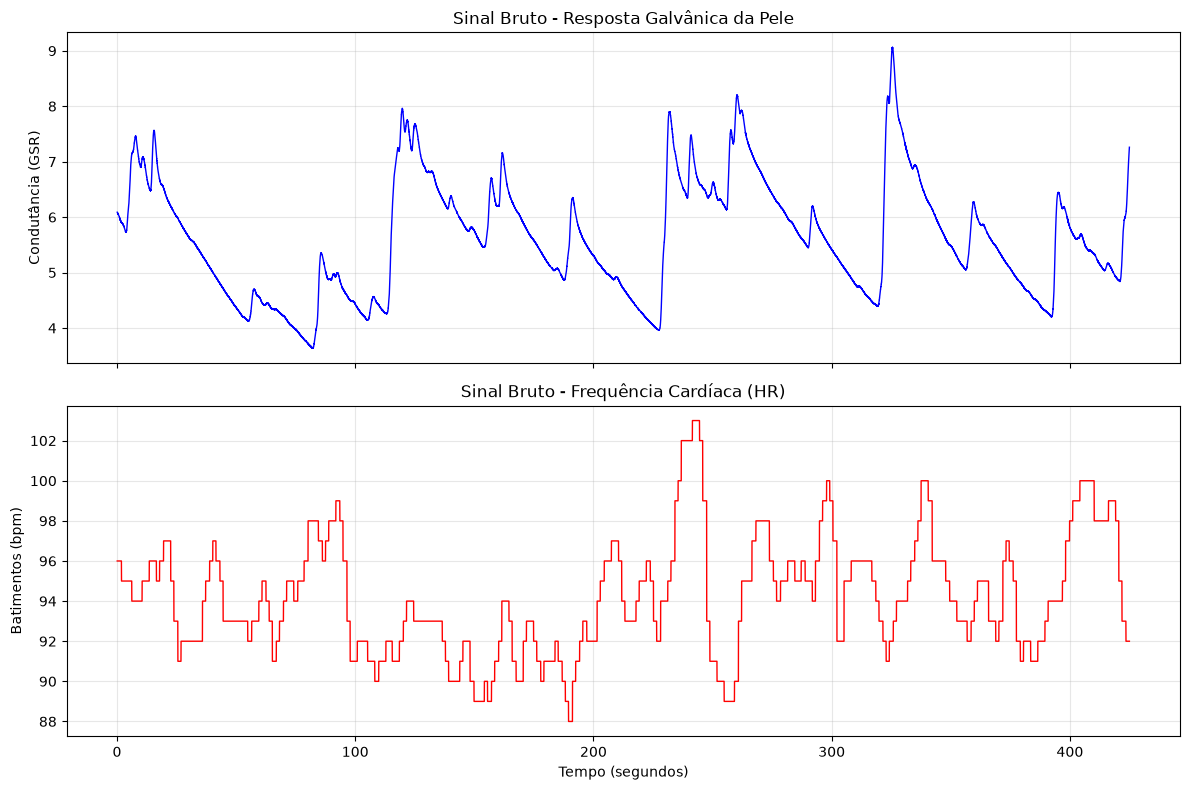

In [4]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# 1. Definir caminhos exatos
BASE_DIR = r"C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI"
SUJEITO = "sub-001"
RUN = "sub-001_ses-01_tk-dm_run-1_nirs_001"
WINGS_FILE = "2026-08-04_002.wings"

caminho_wings = os.path.join(BASE_DIR, SUJEITO, "nirs", RUN, "dados_wings_extraidos", WINGS_FILE)

print(f"A carregar o ficheiro WINGS:\n{caminho_wings}")

# 2. Ler o ficheiro: saltar a 1ª linha ('generation=2') e usar ';' como separador de colunas
df_wings = pd.read_csv(caminho_wings, sep=';', skiprows=1)

# Limpar eventuais espaços em branco nos nomes das colunas
df_wings.columns = df_wings.columns.str.strip()

print(f"\nDados carregados com sucesso! Linhas totais: {len(df_wings)}")
print(f"Colunas ativas: {list(df_wings.columns)}")

# 3. Desenhar os sinais brutos de GSR e HR para inspeção visual inicial
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Gráfico 1: GSR (Resposta Galvânica da Pele)
ax1.plot(df_wings['SecondsSinceRunStart'], df_wings['GSR'], color='blue', linewidth=1)
ax1.set_ylabel('Condutância (GSR)')
ax1.set_title('Sinal Bruto - Resposta Galvânica da Pele')
ax1.grid(True, alpha=0.3)

# Gráfico 2: HR (Frequência Cardíaca)
ax2.plot(df_wings['SecondsSinceRunStart'], df_wings['HR'], color='red', linewidth=1)
ax2.set_xlabel('Tempo (segundos)')
ax2.set_ylabel('Batimentos (bpm)')
ax2.set_title('Sinal Bruto - Frequência Cardíaca (HR)')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 2. Filtragem e Processamento do GSR (Condutância da Pele)
Remoção de ruído de alta frequência (filtro passa-baixo a 5 Hz) e correção do desvio lento da linha de base (drift) para preparar o sinal Galvânico (GSR) para a segmentação por épocas.

A aplicar processamento ao sinal GSR...
Frequência de amostragem (estimada) do SPA-fNIRS: 499.91 Hz


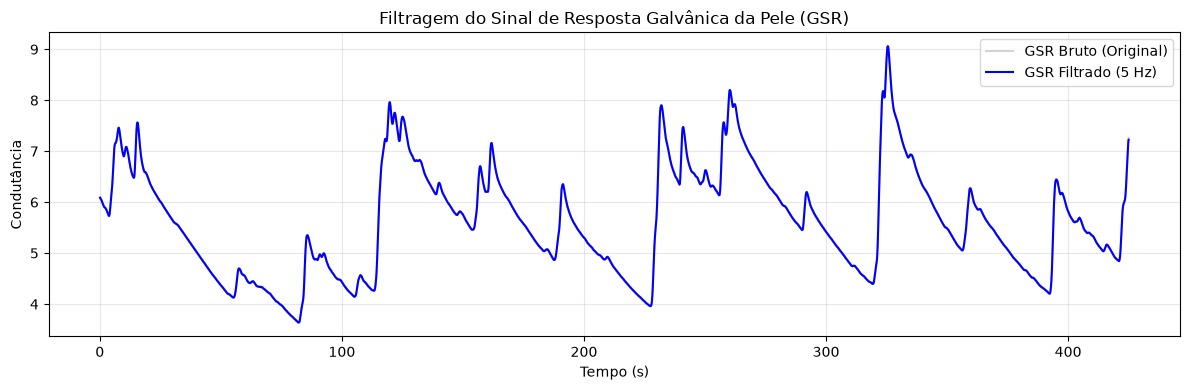

In [5]:
from scipy.signal import butter, filtfilt

print("A aplicar processamento ao sinal GSR...")

# 1. Obter os arrays de tempo e sinal GSR
tempo = df_wings['SecondsSinceRunStart'].values
gsr_bruto = df_wings['GSR'].values

# Frequência de Amostragem do WINGS (precisamos calcular pois o ficheiro não diz)
# Linhas totais a dividir pelo tempo total
fs_wings = len(tempo) / tempo[-1]
print(f"Frequência de amostragem (estimada) do SPA-fNIRS: {fs_wings:.2f} Hz")

# 2. Filtro Passa-Baixo (5 Hz) para remover ruído elétrico/movimento sem matar o sinal fásico
# (O GSR é uma resposta lenta, picos acontecem 1-3 segundos após o estímulo)
cutoff_low = 5.0
nyq = 0.5 * fs_wings
normal_cutoff = cutoff_low / nyq
b, a = butter(4, normal_cutoff, btype='low', analog=False)
gsr_filtrado = filtfilt(b, a, gsr_bruto)

# Adicionar o sinal filtrado ao DataFrame
df_wings['GSR_Filtrado'] = gsr_filtrado

# 3. Desenhar a comparação Bruto vs Filtrado
plt.figure(figsize=(12, 4))
plt.plot(tempo, gsr_bruto, color='lightgray', label='GSR Bruto (Original)')
plt.plot(tempo, gsr_filtrado, color='blue', linewidth=1.5, label='GSR Filtrado (5 Hz)')
plt.title('Filtragem do Sinal de Resposta Galvânica da Pele (GSR)')
plt.xlabel('Tempo (s)')
plt.ylabel('Condutância')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Segmentação por Épocas (Epoching) do GSR
Deteção dos momentos exatos de apresentação dos estímulos de vídeo (`Trigger == 120`) e extração das Épocas da Condutância da Pele. Desenho da Curva Média de Resposta Galvânica (ERP Periférico).

In [7]:
# Analisar a coluna Triggers do WINGS
triggers_unicos = df_wings['Triggers'].unique()

print("Valores únicos encontrados na coluna Triggers do WINGS:")
print(triggers_unicos)

# Contar quantas vezes cada trigger ocorreu (ignorando o 0 que é o baseline longo)
contagem = df_wings[df_wings['Triggers'] != 0]['Triggers'].value_counts()
print("\nContagem de eventos gravados:")
print(contagem)

Valores únicos encontrados na coluna Triggers do WINGS:
[0]

Contagem de eventos gravados:
Series([], Name: count, dtype: int64)


Tempos de início dos vídeos (obtidos do .snirf): [50.311474, 95.462472, 126.338701, 165.066398, 198.745529, 237.671589, 267.628738, 301.197598, 331.970031, 368.08772]
Total de vídeos detetados: 10


<module 'matplotlib.pyplot' from 'c:\\Users\\guilh\\miniconda3\\envs\\NIRS\\Lib\\site-packages\\matplotlib\\pyplot.py'>

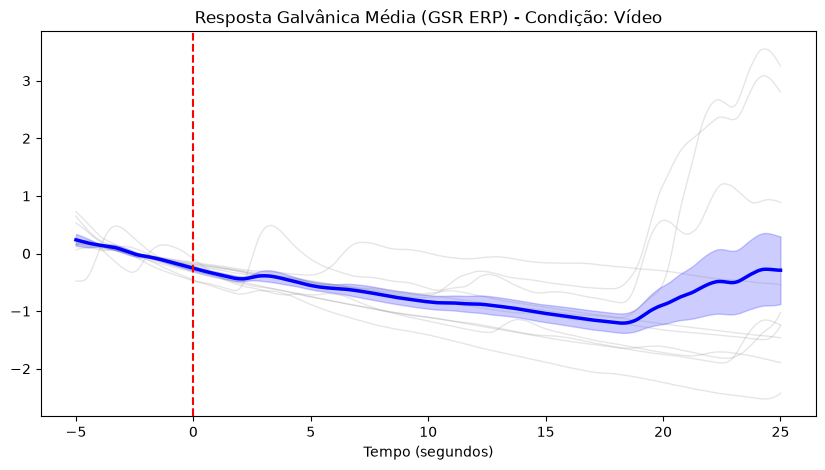

In [8]:
import mne

# 1. Carregar os tempos dos marcadores diretamente do ficheiro .snirf original
# (garantindo que sincronizamos cérebro e corpo pela mesma base temporal)
caminho_snirf_para_triggers = os.path.join(BASE_DIR, SUJEITO, "nirs", RUN, "2026-08-04_002.snirf")
raw_temp = mne.io.read_raw_snirf(caminho_snirf_para_triggers, preload=False, verbose=False)

# Extrair os tempos (em segundos) onde ocorreu o marcador '120' (Vídeo)
tempos_video = []
for onset, duration, desc in zip(raw_temp.annotations.onset, raw_temp.annotations.duration, raw_temp.annotations.description):
    if desc == '120':
        tempos_video.append(onset)

print(f"Tempos de início dos vídeos (obtidos do .snirf): {tempos_video}")
print(f"Total de vídeos detetados: {len(tempos_video)}")

# 2. Encontrar os índices mais próximos no DataFrame do WINGS (a ~500 Hz) para cada tempo de vídeo
tempos_wings = df_wings['SecondsSinceRunStart'].values
indices_video = []

for t in tempos_video:
    # Encontra o índice no array do WINGS cujo tempo está mais próximo do onset do .snirf
    idx_mais_proximo = np.argmin(np.abs(tempos_wings - t))
    indices_video.append(idx_mais_proximo)

# 3. Definir a janela de extração (Epoching) para o GSR
janela_inicio_s = -5.0
janela_fim_s = 25.0

amostras_antes = int(abs(janela_inicio_s) * fs_wings)
amostras_depois = int(janela_fim_s * fs_wings)

epocas_gsr = []
gsr_filtrado = df_wings['GSR_Filtrado'].values

for idx_inicio in indices_video:
    idx_start_epoca = idx_inicio - amostras_antes
    idx_end_epoca = idx_inicio + amostras_depois
    
    if idx_start_epoca >= 0 and idx_end_epoca < len(gsr_filtrado):
        sinal_epoca = gsr_filtrado[idx_start_epoca:idx_end_epoca]
        
        # Correção de Baseline: Subtrair a média dos 5s anteriores
        baseline = np.mean(sinal_epoca[0:amostras_antes])
        sinal_epoca_corrigido = sinal_epoca - baseline
        
        epocas_gsr.append(sinal_epoca_corrigido)

epocas_gsr = np.array(epocas_gsr)

# 4. Desenhar o ERP do GSR
vetor_tempo_epoca = np.linspace(janela_inicio_s, janela_fim_s, len(epocas_gsr[0]))
gsr_medio = np.mean(epocas_gsr, axis=0)
gsr_erro_padrao = np.std(epocas_gsr, axis=0) / np.sqrt(len(epocas_gsr))

plt.figure(figsize=(10, 5))
for epoca in epocas_gsr:
    plt.plot(vetor_tempo_epoca, epoca, color='gray', alpha=0.2, linewidth=1)

plt.plot(vetor_tempo_epoca, gsr_medio, color='blue', linewidth=2.5, label='Média GSR (Event-Related)')
plt.fill_between(vetor_tempo_epoca, gsr_medio - gsr_erro_padrao, gsr_medio + gsr_erro_padrao, color='blue', alpha=0.2, label='Erro Padrão')

plt.axvline(0, color='red', linestyle='--', linewidth=1.5, label='Início do Estímulo (Video)')
plt.title('Resposta Galvânica Média (GSR ERP) - Condição: Vídeo')
plt.xlabel('Tempo (segundos)')
plt

# 4. Segmentação por Épocas (Epoching) da Frequência Cardíaca
Extração das Épocas da Frequência Cardíaca (HR) utilizando os mesmos índices de tempo obtidos pela sincronização com o `.snirf`. Aplicação de correção de *baseline* e desenho da curva média de variação dos batimentos cardíacos (HR ERP).

A construir as Épocas para a Frequência Cardíaca (HR)...


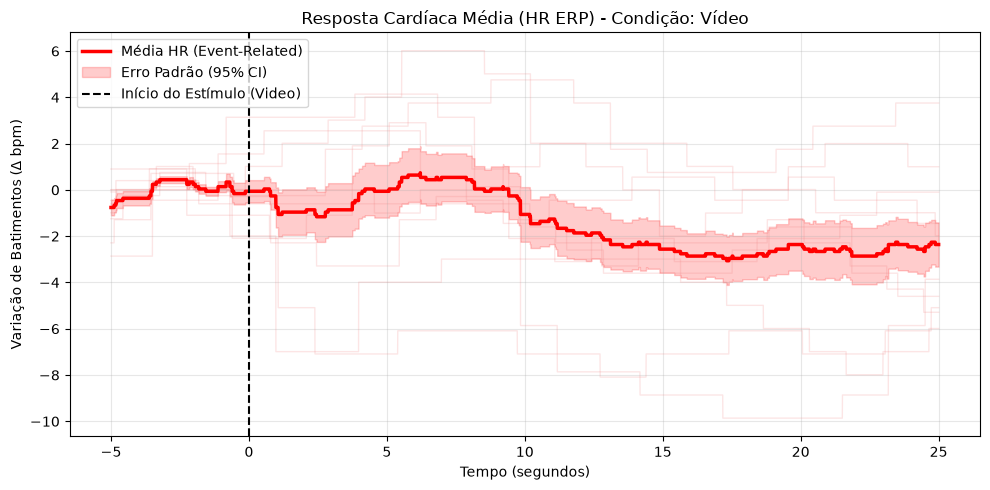

In [9]:
# 1. Obter o sinal bruto de Frequência Cardíaca (HR)
# (O HR do WINGS já vem calculado em bpm)
hr_bruto = df_wings['HR'].values

print("A construir as Épocas para a Frequência Cardíaca (HR)...")

epocas_hr = []

for idx_inicio in indices_video:
    idx_start_epoca = idx_inicio - amostras_antes
    idx_end_epoca = idx_inicio + amostras_depois
    
    # Garantir que a janela não sai fora dos limites do array
    if idx_start_epoca >= 0 and idx_end_epoca < len(hr_bruto):
        sinal_epoca_hr = hr_bruto[idx_start_epoca:idx_end_epoca]
        
        # Correção de Baseline (Frequência Cardíaca)
        # Subtraímos a média dos 5 segundos anteriores para ver a variação (delta bpm)
        baseline_hr = np.mean(sinal_epoca_hr[0:amostras_antes])
        sinal_epoca_corrigido_hr = sinal_epoca_hr - baseline_hr
        
        epocas_hr.append(sinal_epoca_corrigido_hr)

epocas_hr = np.array(epocas_hr)

# 2. Desenhar o ERP da Frequência Cardíaca (HR)
hr_medio = np.mean(epocas_hr, axis=0)
hr_erro_padrao = np.std(epocas_hr, axis=0) / np.sqrt(len(epocas_hr))

plt.figure(figsize=(10, 5))

# Desenhar as épocas individuais (cinzento/vermelho claro)
for epoca in epocas_hr:
    plt.plot(vetor_tempo_epoca, epoca, color='lightcoral', alpha=0.2, linewidth=1)

# Desenhar a curva média com intervalo de erro
plt.plot(vetor_tempo_epoca, hr_medio, color='red', linewidth=2.5, label='Média HR (Event-Related)')
plt.fill_between(vetor_tempo_epoca, hr_medio - hr_erro_padrao, hr_medio + hr_erro_padrao, color='red', alpha=0.2, label='Erro Padrão (95% CI)')

plt.axvline(0, color='black', linestyle='--', linewidth=1.5, label='Início do Estímulo (Video)')
plt.title('Resposta Cardíaca Média (HR ERP) - Condição: Vídeo')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Variação de Batimentos (Δ bpm)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Exportação dos ERPs Periféricos (Derivatives)
Gravação das épocas médias (ERPs) de GSR e Frequência Cardíaca (HR) e dos seus respetivos intervalos de erro num ficheiro CSV estruturado, pronto para integração multi-modal com os dados de fNIRS e análise em grupo.

In [10]:
print("A preparar a exportação dos dados periféricos limpos...")

# 1. Criar um DataFrame agregado com os resultados médios (ERPs) do GSR e HR
df_fisiologia = pd.DataFrame({
    'Tempo_Epoca_s': vetor_tempo_epoca,
    'GSR_Media': gsr_medio,
    'GSR_ErroPadrao': gsr_erro_padrao,
    'HR_Media': hr_medio,
    'HR_ErroPadrao': hr_erro_padrao
})

# 2. Definir o caminho para a pasta derivatives
# (Usamos a mesma pasta derivatives onde guardámos os resultados do fNIRS)
pasta_derivatives = os.path.join(BASE_DIR, "derivatives", "mne-nirs", SUJEITO)
os.makedirs(pasta_derivatives, exist_ok=True)

# 3. Guardar o DataFrame em formato CSV
caminho_csv_fisio = os.path.join(pasta_derivatives, f"{SUJEITO}_{RUN}_fisiologia_erp.csv")
df_fisiologia.to_csv(caminho_csv_fisio, index=False)

print(f"\nResultados dos ERPs Periféricos gravados com sucesso em:\n{caminho_csv_fisio}")
print("\n--- Validação Periférica Single-Subject concluída! ---")

A preparar a exportação dos dados periféricos limpos...

Resultados dos ERPs Periféricos gravados com sucesso em:
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\derivatives\mne-nirs\sub-001\sub-001_sub-001_ses-01_tk-dm_run-1_nirs_001_fisiologia_erp.csv

--- Validação Periférica Single-Subject concluída! ---
